# Tips, airports, and data quality

Pandas builds tip percent, an airport slice, and anomaly flags on the 10k sample. The full-year bars come from the DuckDB extracts in `data/agg/`.

In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import plotly.express as px
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "sql").exists():
    ROOT = ROOT.parent

SAMPLE = ROOT / "data" / "sample" / "yellow_2024_sample_10k.parquet"
ZONES = ROOT / "data" / "sample" / "taxi_zone_lookup.csv"
AGG = ROOT / "data" / "agg"


def show(fig):
    """Store a static render so the notebook is readable without the widget."""
    display(Image(fig.to_image(format="png", width=960, height=520)))

In [2]:
trips = duckdb.sql(f"SELECT * FROM read_parquet('{SAMPLE.as_posix()}')").df()
zones = pd.read_csv(ZONES)
trips["pickup"] = pd.to_datetime(trips["tpep_pickup_datetime"])
trips["dropoff"] = pd.to_datetime(trips["tpep_dropoff_datetime"])
trips["duration_sec"] = (trips["dropoff"] - trips["pickup"]).dt.total_seconds()
print(f"{len(trips):,} sample rows, {trips.shape[1]} columns")
trips.head(3)

10,000 sample rows, 22 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,pickup,dropoff,duration_sec
0,2,2024-11-05 22:30:25,2024-11-05 22:46:57,2,4.18,1,N,87,68,1,...,0.5,2.50,0.0,1.0,28.70,2.5,0.0,2024-11-05 22:30:25,2024-11-05 22:46:57,992.0
1,2,2024-06-06 22:12:08,2024-06-06 22:36:35,<NA>,1.54,<NA>,NaN,237,48,0,...,0.5,0.00,0.0,1.0,28.30,NaN,NaN,2024-06-06 22:12:08,2024-06-06 22:36:35,1467.0
2,2,2024-04-14 01:22:56,2024-04-14 01:36:17,2,2.73,1,N,114,100,1,...,0.5,3.09,0.0,1.0,23.69,2.5,0.0,2024-04-14 01:22:56,2024-04-14 01:36:17,801.0


In [3]:
population = trips[
    trips["pickup"].ge("2024-01-01")
    & trips["pickup"].lt("2025-01-01")
    & trips["duration_sec"].between(1, 10800)
    & trips["trip_distance"].gt(0)
    & trips["trip_distance"].le(100)
    & trips["fare_amount"].gt(0)
    & trips["fare_amount"].le(300)
    & trips["total_amount"].gt(0)
].copy()
print(f"{len(population):,} in-policy sample rows of {len(trips):,}")

9,635 in-policy sample rows of 10,000


## Tip percent by payment type

Tip percent is the tip divided by the pre-tip bill, `tip_amount / (total_amount - tip_amount)`. Payment type 1 is credit card and 2 is cash.

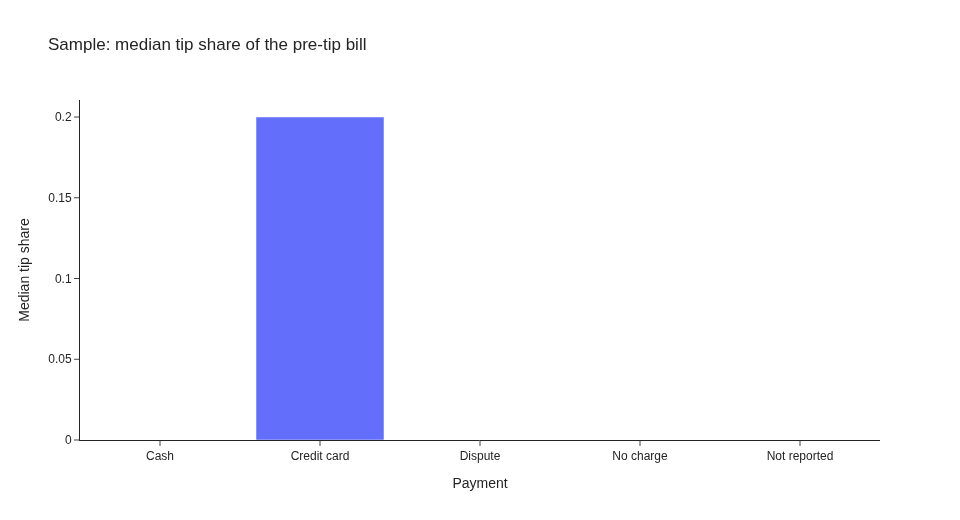

,payment_name,trips,median_tip_pct,pct_with_tip
0,Cash,1234,0.0,0.000000
1,Credit card,7334,0.2,0.939324
2,Dispute,110,0.0,0.009091
3,No charge,47,0.0,0.000000
4,Not reported,910,0.0,0.168132


In [4]:
names = {0: "Not reported", 1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute"}
tipped = population[
    population["payment_type"].isin([0, 1, 2, 3, 4])
    & population["tip_amount"].ge(0)
    & population["total_amount"].gt(population["tip_amount"])
].copy()
tipped["tip_pct"] = tipped["tip_amount"] / (tipped["total_amount"] - tipped["tip_amount"])
tipped["payment_name"] = tipped["payment_type"].map(names)
summary = tipped.groupby("payment_name", as_index=False).agg(
    trips=("tip_pct", "size"),
    median_tip_pct=("tip_pct", "median"),
    pct_with_tip=("tip_amount", lambda s: (s > 0).mean()),
)
fig = px.bar(
    summary,
    x="payment_name",
    y="median_tip_pct",
    title="Sample: median tip share of the pre-tip bill",
    labels={"median_tip_pct": "Median tip share", "payment_name": "Payment"},
)
fig.update_layout(template="simple_white")
show(fig)
summary

Card median tip 20%; cash median tip 0%


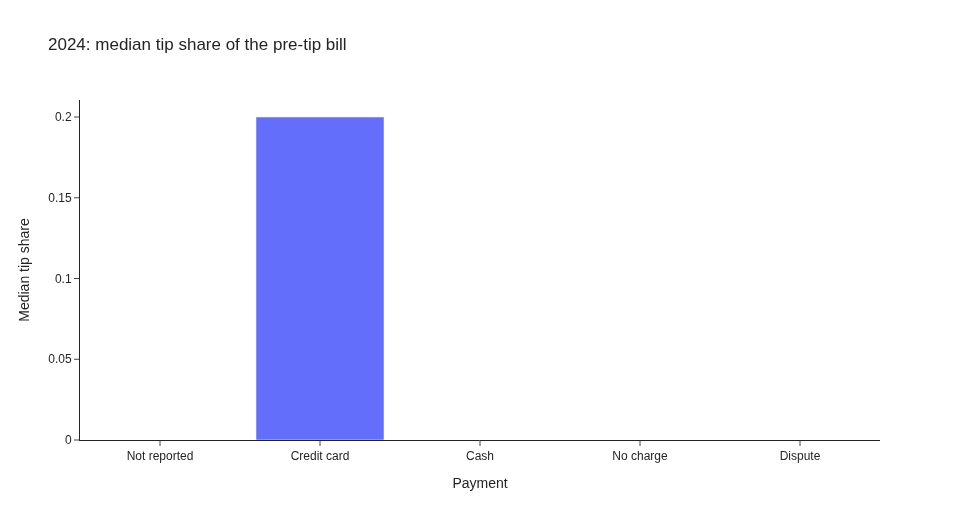

In [5]:
full_tips = pd.read_csv(AGG / "04_tip_by_payment.csv")
fig = px.bar(
    full_tips,
    x="payment_name",
    y="median_tip_pct",
    title="2024: median tip share of the pre-tip bill",
    labels={"median_tip_pct": "Median tip share", "payment_name": "Payment"},
)
fig.update_layout(template="simple_white")
card = full_tips.loc[full_tips["payment_type"] == 1].iloc[0]
cash = full_tips.loc[full_tips["payment_type"] == 2].iloc[0]
print(f"Card median tip {card['median_tip_pct']:.0%}; cash median tip {cash['median_tip_pct']:.0%}")
show(fig)

## Airport products

JFK is zone 132, LaGuardia is 138, Newark is 1. Rate code 2 is the JFK flat fare.

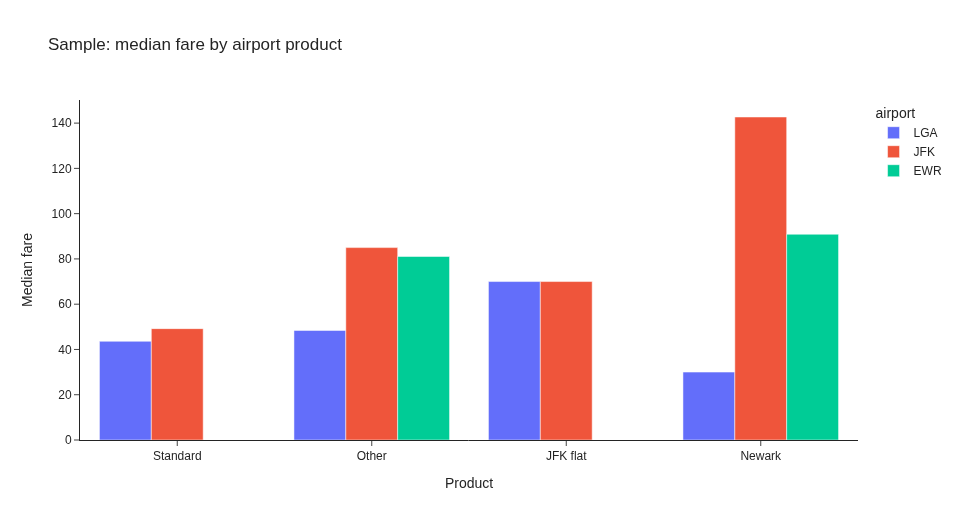

,airport,product,trips,median_fare
9,LGA,Standard,389,43.6
2,JFK,JFK flat,297,70.0
5,JFK,Standard,210,49.2
4,JFK,Other,39,85.0
8,LGA,Other,19,48.4
0,EWR,Newark,19,90.9
3,JFK,Newark,4,142.7
6,LGA,JFK flat,3,70.0


In [6]:
airports = {1: "EWR", 132: "JFK", 138: "LGA"}
airport_trips = population[
    population["PULocationID"].isin(airports) | population["DOLocationID"].isin(airports)
].copy()
airport_trips["airport"] = airport_trips["PULocationID"].map(airports)
airport_trips["airport"] = airport_trips["airport"].fillna(
    airport_trips["DOLocationID"].map(airports)
)
airport_trips["product"] = (
    airport_trips["RatecodeID"].map({1: "Standard", 2: "JFK flat", 3: "Newark"}).fillna("Other")
)
by_product = (
    airport_trips.groupby(["airport", "product"], as_index=False)
    .agg(trips=("fare_amount", "size"), median_fare=("fare_amount", "median"))
    .sort_values("trips", ascending=False)
)
fig = px.bar(
    by_product,
    x="product",
    y="median_fare",
    color="airport",
    barmode="group",
    title="Sample: median fare by airport product",
    labels={"median_fare": "Median fare", "product": "Product"},
)
fig.update_layout(template="simple_white")
show(fig)
by_product.head(8)

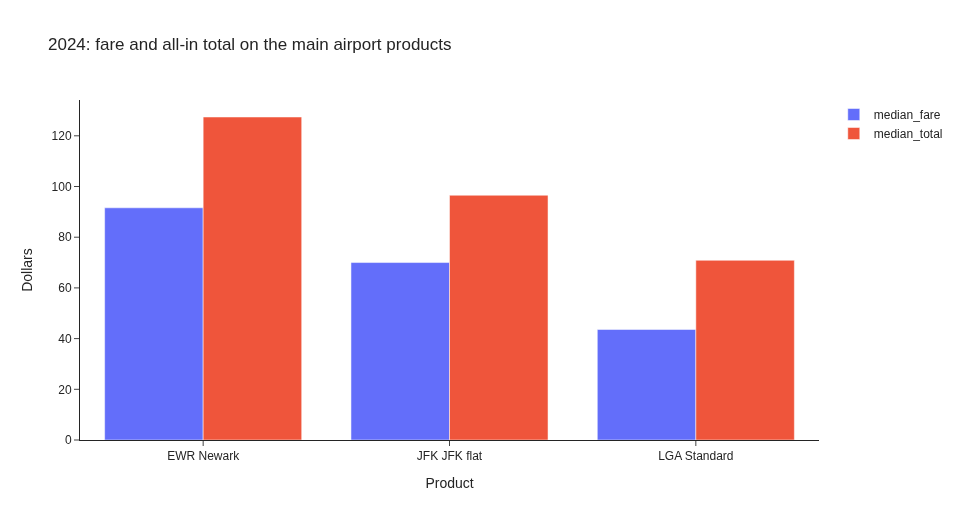

,airport,product,direction,trips,median_fare,median_total,median_miles
0,EWR,Newark,from Manhattan,83258,91.6,127.42,17.72
22,JFK,JFK flat,to Manhattan,969304,70.0,96.55,18.16
47,LGA,Standard,to Manhattan,876642,43.6,70.89,9.54


In [7]:
full_airport = pd.read_csv(AGG / "05_airport_economics.csv")
focus = full_airport[
    (
        (full_airport["airport"] == "JFK")
        & (full_airport["product"] == "JFK flat")
        & (full_airport["direction"] == "to Manhattan")
    )
    | (
        (full_airport["airport"] == "LGA")
        & (full_airport["product"] == "Standard")
        & (full_airport["direction"] == "to Manhattan")
    )
    | (
        (full_airport["airport"] == "EWR")
        & (full_airport["product"] == "Newark")
        & (full_airport["direction"] == "from Manhattan")
    )
].copy()
focus["label"] = focus["airport"] + " " + focus["product"]
fig = px.bar(
    focus,
    x="label",
    y=["median_fare", "median_total"],
    barmode="group",
    title="2024: fare and all-in total on the main airport products",
    labels={"value": "Dollars", "label": "Product", "variable": ""},
)
fig.update_layout(template="simple_white")
show(fig)
focus[["airport", "product", "direction", "trips", "median_fare", "median_total", "median_miles"]]

## Anomaly flags

The same rules as `sql/07_anomaly_rules.sql`, expressed as pandas masks on the sample. A row can trip more than one.

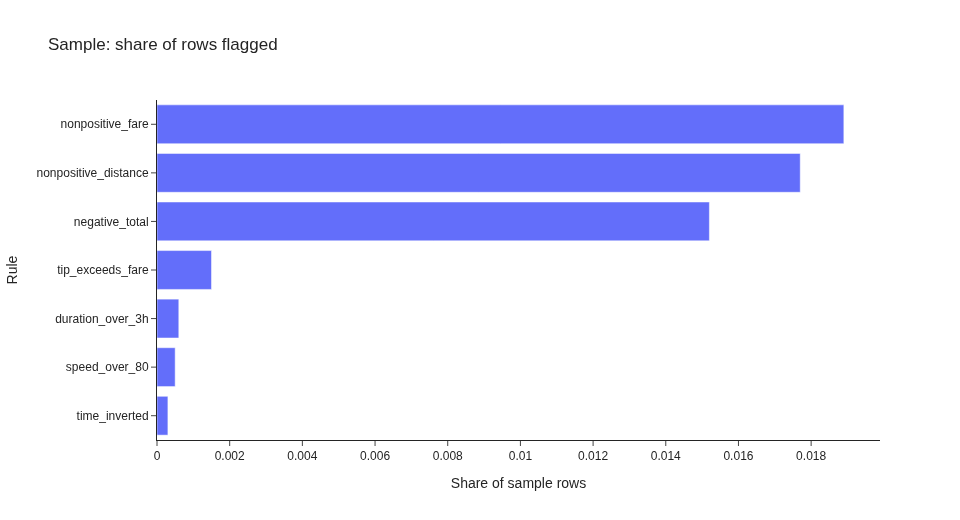

,rule,flag_rate
3,time_inverted,0.0003
5,speed_over_80,0.0005
4,duration_over_3h,0.0006
6,tip_exceeds_fare,0.0015
2,negative_total,0.0152
0,nonpositive_distance,0.0177
1,nonpositive_fare,0.0189


In [8]:
rules = pd.DataFrame(
    {
        "nonpositive_distance": trips["trip_distance"].le(0),
        "nonpositive_fare": trips["fare_amount"].le(0),
        "negative_total": trips["total_amount"].lt(0),
        "time_inverted": trips["dropoff"].le(trips["pickup"]),
        "duration_over_3h": trips["duration_sec"].gt(10800),
        "speed_over_80": (trips["trip_distance"] / (trips["duration_sec"] / 3600)).gt(80),
        "tip_exceeds_fare": trips["fare_amount"].gt(0)
        & trips["tip_amount"].gt(trips["fare_amount"]),
    }
)
rates = rules.mean().rename_axis("rule").reset_index(name="flag_rate")
rates = rates.sort_values("flag_rate")
fig = px.bar(
    rates,
    x="flag_rate",
    y="rule",
    orientation="h",
    title="Sample: share of rows flagged",
    labels={"flag_rate": "Share of sample rows", "rule": "Rule"},
)
fig.update_layout(template="simple_white")
show(fig)
rates

## Completeness on the full file

Vendor feed 4,091,232 rows (9.9%); excluded from KPIs 1,494,442 (3.6%)


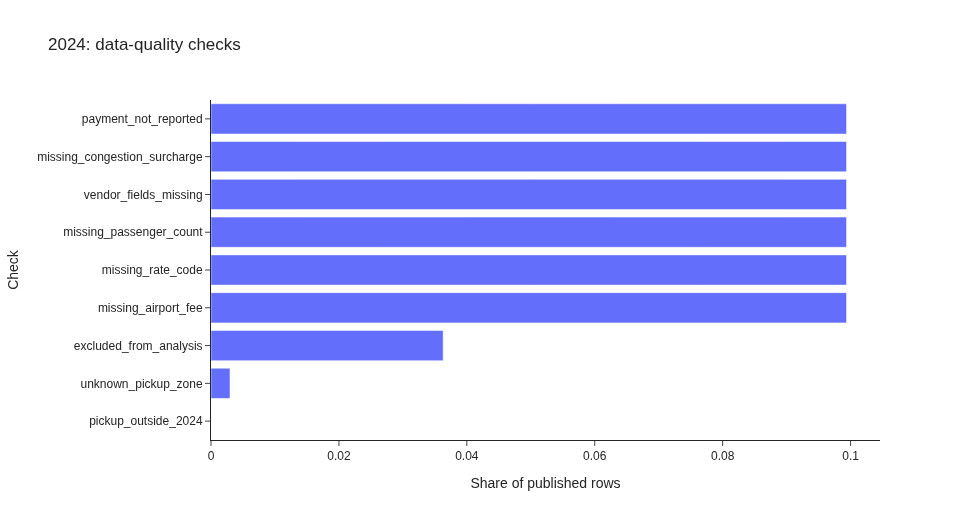

In [9]:
quality = pd.read_csv(AGG / "01_data_quality.csv").sort_values("flag_rate")
fig = px.bar(
    quality,
    x="flag_rate",
    y="check_name",
    orientation="h",
    title="2024: data-quality checks",
    labels={"flag_rate": "Share of published rows", "check_name": "Check"},
)
fig.update_layout(template="simple_white", yaxis={"categoryorder": "total ascending"})
vendor = quality.loc[quality["check_name"] == "vendor_fields_missing"].iloc[0]
excluded = quality.loc[quality["check_name"] == "excluded_from_analysis"].iloc[0]
print(
    f"Vendor feed {int(vendor['flagged']):,} rows ({vendor['flag_rate']:.1%}); "
    f"excluded from KPIs {int(excluded['flagged']):,} ({excluded['flag_rate']:.1%})"
)
show(fig)